<a href="https://colab.research.google.com/github/anisha-dev26/BIS_LAB-1BF24CS054-/blob/main/GreyWolfOptimizer(Feature_Selection).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET INFORMATION
-------------------
Total samples: 569
Total features: 30
Classes: ['malignant' 'benign']

MTBGWO OPTIMIZATION STARTED
--------------------------------
Generation 01 | Best Fitness = 0.032952
Generation 02 | Best Fitness = 0.032952
Generation 03 | Best Fitness = 0.032952
Generation 04 | Best Fitness = 0.032952
Generation 05 | Best Fitness = 0.031443
Generation 06 | Best Fitness = 0.030443
Generation 07 | Best Fitness = 0.030443
Generation 08 | Best Fitness = 0.030443
Generation 09 | Best Fitness = 0.030443
Generation 10 | Best Fitness = 0.026601
Generation 11 | Best Fitness = 0.026601
Generation 12 | Best Fitness = 0.026601
Generation 13 | Best Fitness = 0.026601
Generation 14 | Best Fitness = 0.022582
Generation 15 | Best Fitness = 0.022582
Generation 16 | Best Fitness = 0.022582
Generation 17 | Best Fitness = 0.022582
Generation 18 | Best Fitness = 0.022249
Generation 19 | Best Fitness = 0.022249
Generation 20 | Best Fitness = 0.022249
Generation 21 | Best Fitness

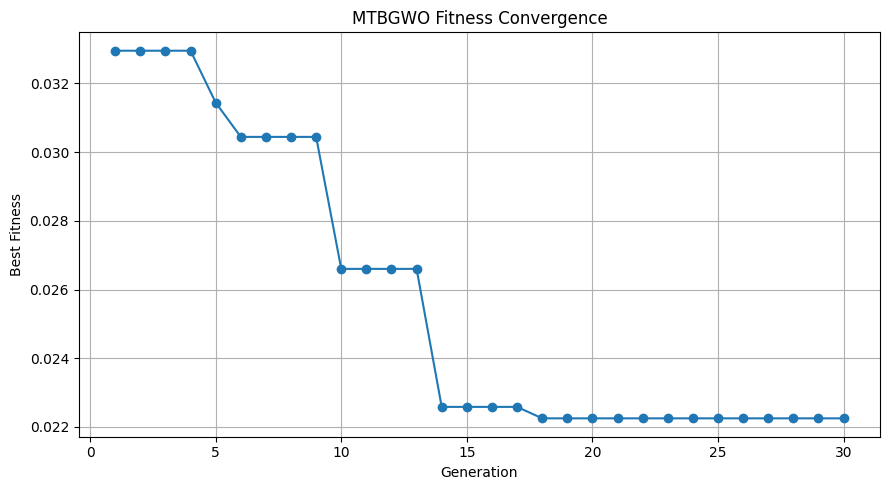

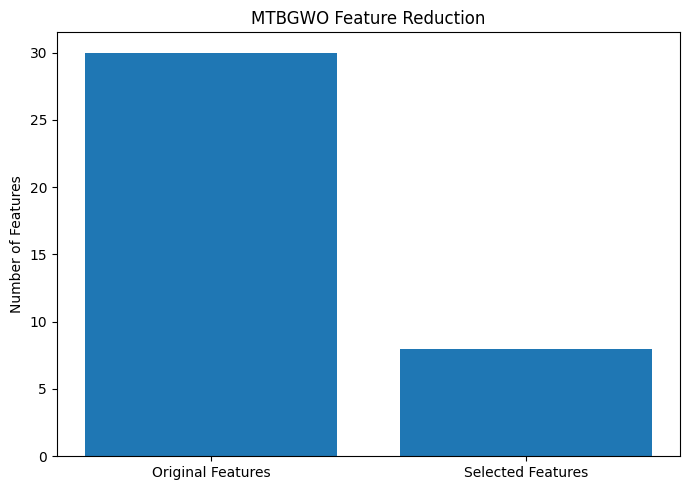


MTBGWO EXECUTION COMPLETED!


In [1]:

# MTBGWO: Multi-Elite Interaction Threshold Binary Grey Wolf Optimizer
# Application: Feature Selection using Breast Cancer Dataset

!pip install -q numpy pandas matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# --------------------------------------------------
# 1. LOAD DATASET
# --------------------------------------------------

data = load_breast_cancer()

X = data.data
y = data.target
feature_names = data.feature_names

print("DATASET INFORMATION")
print("-------------------")
print("Total samples:", X.shape[0])
print("Total features:", X.shape[1])
print("Classes:", data.target_names)

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# --------------------------------------------------
# 2. ALGORITHM PARAMETERS
# --------------------------------------------------

POPULATION_SIZE = 24
NUM_GROUPS = 4
MAX_ITERATIONS = 30

PHI = 0.99
MU = 0.01

NUM_FEATURES = X_train.shape[1]

rng = np.random.default_rng(42)

# Each wolf has a continuous position between 0 and 1
wolves = rng.random((POPULATION_SIZE, NUM_FEATURES))

# Divide wolves into equal sub-populations
groups = np.array_split(np.arange(POPULATION_SIZE), NUM_GROUPS)

# KNN classifier with k=5 as used in the research paper
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cache fitness values to avoid repeated calculations
fitness_cache = {}

# --------------------------------------------------
# 3. THRESHOLD BINARIZATION
# --------------------------------------------------

def binary_conversion(position):

    binary = (position >= 0.5).astype(int)

    # Ensure at least one feature is selected
    if np.sum(binary) == 0:
        binary[np.argmax(position)] = 1

    return binary


# --------------------------------------------------
# 4. FITNESS FUNCTION
# --------------------------------------------------

def fitness_function(position):

    binary = binary_conversion(position)

    key = tuple(binary)

    if key in fitness_cache:
        return fitness_cache[key]

    selected_indices = np.where(binary == 1)[0]

    X_selected = X_train[:, selected_indices]

    # KNN classifier with standardization
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5))
    ])

    # Calculate cross-validation accuracy
    scores = cross_val_score(
        model,
        X_selected,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    accuracy = np.mean(scores)

    error = 1 - accuracy

    feature_ratio = len(selected_indices) / NUM_FEATURES

    # Research paper fitness equation
    fitness = (
        PHI * error +
        MU * feature_ratio
    )

    fitness_cache[key] = fitness

    return fitness


# --------------------------------------------------
# 5. FIND BEST WOLF IN EACH SUB-POPULATION
# --------------------------------------------------

def find_elites():

    elite_positions = []
    elite_fitness = []
    elite_indices = []

    for group in groups:

        scores = [
            fitness_function(wolves[i])
            for i in group
        ]

        best_local = np.argmin(scores)

        best_index = group[best_local]

        elite_positions.append(wolves[best_index].copy())
        elite_fitness.append(scores[best_local])
        elite_indices.append(best_index)

    return elite_positions, elite_fitness, elite_indices


# --------------------------------------------------
# 6. MULTI-ELITE INTERACTION
# --------------------------------------------------

def multi_elite_interaction(
    elite_positions,
    elite_fitness,
    elite_indices
):

    for i in range(NUM_GROUPS):

        # Collect elite positions from other groups
        other_elites = [
            elite_positions[j]
            for j in range(NUM_GROUPS)
            if j != i
        ]

        # Mean of other elite positions
        mean_position = np.mean(other_elites, axis=0)

        # Gaussian random interaction N(0,1)
        new_position = mean_position * (
            1 + rng.normal(0, 1, NUM_FEATURES)
        )

        # Keep positions within [0,1]
        new_position = np.clip(new_position, 0, 1)

        new_fitness = fitness_function(new_position)

        # Replace local elite if the new solution is better
        if new_fitness < elite_fitness[i]:

            wolves[elite_indices[i]] = new_position

            elite_positions[i] = new_position.copy()

            elite_fitness[i] = new_fitness


# --------------------------------------------------
# 7. GREY WOLF POSITION UPDATE
# --------------------------------------------------

def update_wolves(iteration, elite_positions):

    # Parameter decreases linearly from 2 to 0
    a = 2 - (2 * iteration / MAX_ITERATIONS)

    for group_number, group in enumerate(groups):

        # Best wolf (alpha) of this sub-population
        alpha = elite_positions[group_number]

        for wolf_index in group:

            current_position = wolves[wolf_index].copy()

            r1 = rng.random(NUM_FEATURES)
            r2 = rng.random(NUM_FEATURES)

            A = 2 * a * r1 - a
            C = 2 * r2

            # Distance between wolf and alpha wolf
            D = np.abs(C * alpha - current_position)

            # Position update using alpha wolf only
            new_position = alpha - A * D

            # Restrict continuous position to [0,1]
            new_position = np.clip(new_position, 0, 1)

            wolves[wolf_index] = new_position


# --------------------------------------------------
# 8. MAIN MTBGWO OPTIMIZATION
# --------------------------------------------------

best_position = None
best_fitness = float("inf")

generation_history = []

print("\nMTBGWO OPTIMIZATION STARTED")
print("--------------------------------")

for iteration in range(MAX_ITERATIONS):

    # Find best wolf of each sub-population
    elite_positions, elite_fitness, elite_indices = find_elites()

    # Multi-elite information interaction
    multi_elite_interaction(
        elite_positions,
        elite_fitness,
        elite_indices
    )

    # Update wolf positions
    update_wolves(iteration, elite_positions)

    # Evaluate all wolves
    current_scores = [
        fitness_function(wolf)
        for wolf in wolves
    ]

    generation_best_index = np.argmin(current_scores)

    generation_best_fitness = current_scores[
        generation_best_index
    ]

    # Maintain global best solution
    if generation_best_fitness < best_fitness:

        best_fitness = generation_best_fitness

        best_position = wolves[
            generation_best_index
        ].copy()

    generation_history.append(best_fitness)

    print(
        f"Generation {iteration + 1:02d} | "
        f"Best Fitness = {best_fitness:.6f}"
    )


# --------------------------------------------------
# 9. FINAL FEATURE SELECTION
# --------------------------------------------------

best_binary = binary_conversion(best_position)

selected_indices = np.where(best_binary == 1)[0]

selected_features = feature_names[selected_indices]

print("\nFINAL OPTIMIZATION RESULTS")
print("--------------------------------")

print("Best Fitness:", round(best_fitness, 6))

print("Total Features:", NUM_FEATURES)

print("Selected Features:", len(selected_indices))

print("Feature Reduction:",
      round((1 - len(selected_indices) / NUM_FEATURES) * 100, 2),
      "%")

print("\nSELECTED FEATURES:")

for feature in selected_features:
    print("-", feature)


# --------------------------------------------------
# 10. FINAL CLASSIFICATION PERFORMANCE
# --------------------------------------------------

X_train_selected = X_train[:, selected_indices]
X_test_selected = X_test[:, selected_indices]

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

final_model.fit(X_train_selected, y_train)

y_pred = final_model.predict(X_test_selected)

final_accuracy = accuracy_score(y_test, y_pred)

print("\nCLASSIFICATION RESULTS")
print("--------------------------------")

print("Test Accuracy:",
      round(final_accuracy * 100, 2), "%")


# --------------------------------------------------
# 11. GENERATION-WISE FITNESS TABLE
# --------------------------------------------------

results = pd.DataFrame({
    "Generation": range(1, MAX_ITERATIONS + 1),
    "Best Fitness": generation_history
})

print("\nGENERATION-WISE FITNESS")
print(results.to_string(index=False))


# --------------------------------------------------
# 12. CONVERGENCE GRAPH
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, MAX_ITERATIONS + 1),
    generation_history,
    marker="o"
)

plt.title("MTBGWO Fitness Convergence")
plt.xlabel("Generation")
plt.ylabel("Best Fitness")

plt.grid(True)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 13. FEATURE SELECTION GRAPH
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    ["Original Features", "Selected Features"],
    [NUM_FEATURES, len(selected_indices)]
)

plt.title("MTBGWO Feature Reduction")
plt.ylabel("Number of Features")

plt.tight_layout()
plt.show()

print("\nMTBGWO EXECUTION COMPLETED!")
